# Capítulo 3 · Transformación, codificación y escalado

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/lectures/chapter_03/05_transformacion_y_escalado.ipynb)

**Preprocesamiento para Machine Learning · Parte 2 de 2**

---

### ¿Dónde estamos?

En la clase anterior dejamos los datos **limpios**. Pero un modelo todavía no puede usarlos: necesita que **todo sea numérico**, que las variables estén en **escalas comparables** y que el preprocesamiento se haga **sin hacer trampa** con los datos de test.

```
datos crudos → diagnóstico → limpieza estructural → valores faltantes → outliers     ← clase anterior
             → transformación → codificación → escalado → train/test → modelo        ← esta clase
```

### 🎯 Objetivos
1. Transformar variables asimétricas con un logaritmo y crear variables nuevas.
2. Codificar variables categóricas: one-hot y ordinal.
3. Escalar variables numéricas: normalización y estandarización.
4. Separar train y test, y preparar los datos en el orden correcto.
5. Unir todo el preprocesamiento en un `Pipeline` de scikit-learn.

### 📚 Índice
1. Punto de partida
2. Transformar variables
3. Codificar variables categóricas
4. Escalar variables numéricas
5. Separar train y test
6. Todo junto: `ColumnTransformer` y `Pipeline`
7. Chuleta resumen

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import set_config
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, MinMaxScaler, OneHotEncoder,
                                   OrdinalEncoder, StandardScaler)

# Que scikit-learn devuelva DataFrames (con nombres de columna) en lugar de arrays de NumPy
set_config(transform_output="pandas")

# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"

---
## 1. Punto de partida

Volvemos a cargar `viviendas_sucio.csv` y aplicamos de golpe la limpieza de la clase anterior. Para centrarnos en lo nuevo, en lugar de imputar **eliminamos las filas con valores faltantes**.

In [2]:
df = pd.read_csv(DATA_DIR / "viviendas_sucio.csv")

# Limpieza de la clase anterior
df = df.drop_duplicates()
df["barrio"] = df["barrio"].str.strip().str.capitalize()
df["precio"] = pd.to_numeric(df["precio"].str.replace("$", "", regex=False).str.replace(",", "", regex=False))
df["fecha_venta"] = pd.to_datetime(df["fecha_venta"])

df = df.dropna()
errores = df["precio"] / df["metros"] > 10_000
df = df[~errores]

print("Filas:", len(df), "| Nulos:", df.isna().sum().sum())

Filas: 527 | Nulos: 0


---
## 2. Transformar variables

### 2.1 Variables asimétricas: el logaritmo

En la clase anterior vimos que `distancia_metro_m` tiene una **cola muy larga**: casi todas las viviendas están cerca del metro y unas pocas, muy lejos. Muchos modelos funcionan peor con distribuciones así, porque los pocos valores enormes dominan los cálculos.

El logaritmo **comprime los valores grandes** y deja casi igual los pequeños: 100 → 4.6, 1.000 → 6.9, 10.000 → 9.2. Usamos `np.log1p(x)`, que calcula $\log(1 + x)$ y así funciona también con ceros.

Para medir la asimetría usamos `.skew()`: **0 es simétrica**; cuanto más lejos de 0, más asimétrica.

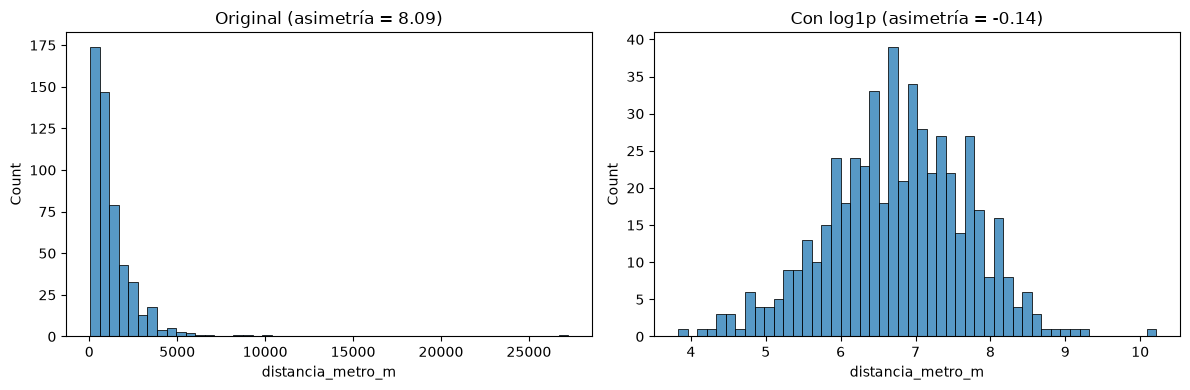

In [3]:
distancia_log = np.log1p(df["distancia_metro_m"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["distancia_metro_m"], bins=50, ax=axes[0])
axes[0].set_title(f"Original (asimetría = {df['distancia_metro_m'].skew():.2f})")
sns.histplot(distancia_log, bins=50, ax=axes[1])
axes[1].set_title(f"Con log1p (asimetría = {distancia_log.skew():.2f})")
plt.tight_layout()
plt.show()

Tras el logaritmo, la distribución es casi simétrica. **No perdemos ninguna fila** y el orden se mantiene: la vivienda más lejana sigue siendo la más lejana.

> 💡 Todavía no guardamos la columna transformada: el logaritmo lo aplicará el `Pipeline` en la sección 6.

### 2.2 Crear variables nuevas (*feature engineering*)

A veces la información útil está "escondida" en otras columnas. Crear variables nuevas a partir de las que ya tienes es una de las cosas que más mejora un modelo:

In [4]:
# De una fecha, un modelo no puede sacar nada; de sus partes, sí
df["año_venta"] = df["fecha_venta"].dt.year
df["mes_venta"] = df["fecha_venta"].dt.month

# Una proporción: ¿son habitaciones grandes o pequeñas?
df["metros_por_habitacion"] = df["metros"] / df["habitaciones"]

df[["fecha_venta", "año_venta", "mes_venta", "metros", "habitaciones", "metros_por_habitacion"]].head()

,fecha_venta,año_venta,mes_venta,metros,habitaciones,metros_por_habitacion
0,2022-10-24,2022,10,104.0,2,52.0
1,2024-04-12,2024,4,74.0,1,74.0
2,2023-09-12,2023,9,174.0,5,34.8
3,2024-11-02,2024,11,89.0,1,89.0
4,2023-10-12,2023,10,114.0,4,28.5


> ⚠️ **Nunca crees variables a partir del *target*** (la variable que quieres predecir). En la clase anterior usamos el precio por m² para **detectar errores**, pero no puede ser una variable del modelo: para calcularla hace falta el precio, que es justo lo que el modelo tiene que adivinar. Sería hacer trampa.

### 2.3 Agrupar en tramos (*binning*)

Con `pd.cut` (lo viste en pandas) una variable numérica se convierte en categórica. Es útil cuando lo que importa es el tramo y no el valor exacto:

In [5]:
tramos = pd.cut(df["antiguedad"], bins=[-1, 10, 30, 100], labels=["nueva", "media", "antigua"])
tramos.value_counts()

antiguedad
antigua    246
media      187
nueva       94
Name: count, dtype: int64

> 💡 Agrupar en tramos **pierde información** (una vivienda de 11 años y una de 30 quedan iguales). Úsalo solo si tiene sentido para el problema; por defecto, deja la variable numérica.

---
## 3. Codificar variables categóricas ⭐

Los modelos solo entienden números, así que hay que convertir las categorías. Pero **no todas las categorías son iguales**:

| Tipo | Ejemplo | ¿Hay un orden? | Codificación |
|---|---|---|---|
| **Nominal** | `barrio`: Centro, Norte, Sur… | No | One-hot |
| **Binaria** | `garaje`: sí / no | — | 0 / 1 |
| **Ordinal** | `estado`: a reformar < buen estado < como nuevo | Sí | Números en orden |

### 3.1 ¿Por qué no numerar las categorías sin más?

Si codificáramos `Centro=0, Este=1, Norte=2, Oeste=3, Sur=4`, el modelo entendería que el Sur es "cuatro veces" el Este, o que el Norte está "entre" el Este y el Oeste. **Nos inventaríamos un orden que no existe.**

### 3.2 One-hot encoding

Crea **una columna binaria por categoría**: 1 si la fila es de esa categoría, 0 si no. Con pandas se hace con `pd.get_dummies`:

In [6]:
pd.get_dummies(df["barrio"], prefix="barrio", dtype=int).head()

,barrio_Centro,barrio_Este,barrio_Norte,barrio_Oeste,barrio_Sur
0,1,0,0,0,0
1,0,0,0,0,1
2,0,1,0,0,0
3,1,0,0,0,0
4,0,0,0,1,0


Cada fila tiene **exactamente un 1**. Por eso una columna sobra: si no es Centro, Este, Norte ni Oeste, tiene que ser Sur. Con `drop_first=True` se elimina la primera:

In [7]:
pd.get_dummies(df["barrio"], prefix="barrio", drop_first=True, dtype=int).head()

,barrio_Este,barrio_Norte,barrio_Oeste,barrio_Sur
0,0,0,0,0
1,0,0,0,1
2,1,0,0,0
3,0,0,0,0
4,0,0,1,0


> 💡 `drop_first=True` importa sobre todo en modelos lineales (como la regresión lineal), donde una columna redundante causa problemas. Para muchos otros modelos da igual.

Una variable **binaria** es un caso particular: basta con una columna de 0 y 1.

In [8]:
df["garaje"].map({"no": 0, "sí": 1}).head()

0    1
1    0
2    1
3    1
4    0
Name: garaje, dtype: int64

### 3.3 Codificación ordinal

Cuando **sí** hay un orden, lo respetamos con números que lo reflejen:

In [9]:
orden_estado = {"a reformar": 0, "buen estado": 1, "como nuevo": 2}
df["estado"].map(orden_estado).value_counts(dropna=False)

estado
1    219
0    170
2    138
Name: count, dtype: int64

### 3.4 Con scikit-learn

**`OneHotEncoder`** hace lo mismo que `get_dummies`, pero con `fit` y `transform`: en `fit` **aprende qué categorías existen** y en `transform` las aplica. Eso tiene una ventaja enorme: ¿qué pasa si mañana llega una vivienda de un barrio que no estaba en los datos?

In [10]:
codificador = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
codificador.fit(df[["barrio"]])
print("Categorías aprendidas:", codificador.categories_)

nuevas = pd.DataFrame({"barrio": ["Norte", "Puerto"]})   # "Puerto" no estaba en los datos
codificador.transform(nuevas)

Categorías aprendidas: [array(['Centro', 'Este', 'Norte', 'Oeste', 'Sur'], dtype=object)]


,barrio_Centro,barrio_Este,barrio_Norte,barrio_Oeste,barrio_Sur
0,0.0,0.0,1.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0


Con `handle_unknown="ignore"`, una categoría desconocida queda con **todas las columnas a 0** en lugar de dar error. Con `get_dummies`, en cambio, los datos nuevos tendrían **otras columnas** distintas a las del entrenamiento.

**`OrdinalEncoder`** codifica en orden. ¡Pero cuidado con qué orden usa!

In [11]:
tallas = pd.DataFrame({"talla": ["bajo", "medio", "alto", "medio"]})

print("Orden por defecto (alfabético):", OrdinalEncoder().fit(tallas).categories_)
print("Orden indicado:                ", OrdinalEncoder(categories=[["bajo", "medio", "alto"]]).fit(tallas).categories_)

Orden por defecto (alfabético): [array(['alto', 'bajo', 'medio'], dtype=object)]
Orden indicado:                 [array(['bajo', 'medio', 'alto'], dtype=object)]


> ⚠️ Por defecto, `OrdinalEncoder` ordena las categorías **alfabéticamente**: alto < bajo < medio. ¡Sin sentido! Indica siempre el orden con `categories=`.

El **one-hot encoding** (o codificación en caliente) es una **técnica de preprocesamiento de datos** que se utiliza para **convertir variables categóricas (texto o etiquetas) en un formato numérico** binario. Esto permite que los algoritmos de aprendizaje automático (Machine Learning) e inteligencia artificial puedan interpretar y procesar la información correctamente, ya que la mayoría de ellos solo aceptan datos matemáticos y no cadenas de texto.

### ¿Cómo funciona?
El proceso consiste en **crear una nueva columna por cada categoría única** que exista en la variable original. Para cada fila o registro, la columna que corresponde a su categoría recibe un valor de **1** (encendido/hot), mientras que el resto de las nuevas columnas reciben un **0** (apagado).

#### Ejemplo práctico:
Imagina que tienes una columna llamada `Color` con tres opciones posibles: **Rojo**, **Verde** y **Azul**. Al aplicar *one-hot encoding*, la tabla se transforma de la siguiente manera:

| Datos Originales (`Color`) | Color_Rojo | Color_Verde | Color_Azul |
| :--- | :---: | :---: | :---: |
| **Rojo** | 1 | 0 | 0 |
| **Verde** | 0 | 1 | 0 |
| **Azul** | 0 | 0 | 1 |
| **Rojo** | 1 | 0 | 0 |

### ¿Por qué se usa en lugar de solo asignar números (1, 2, 3)?
Existe otra alternativa llamada *Label Encoding* que simplemente asigna un número a cada palabra (ej. Rojo = 1, Verde = 2, Azul = 3). Sin embargo, esto causa problemas porque **los modelos matemáticos asumen que hay un orden jerárquico**. El algoritmo podría interpretar erróneamente que "Azul (3)" vale más que "Rojo (1)" o que la distancia entre ellos tiene un significado real. El *one-hot encoding* evita este sesgo al mantener todas las categorías en un plano de igualdad numérica.

### Ventajas y Limitaciones
* **Ventaja:** No introduce relaciones de orden inexistentes y es totalmente compatible con modelos lineales, redes neuronales y algoritmos basados en distancias.
* **Desventaja (La maldición de la dimensionalidad):** Si una columna de texto tiene miles de categorías únicas (por ejemplo, códigos postales o nombres de productos), el *one-hot encoding* creará miles de columnas nuevas. Esto genera una matriz muy grande y vacía (datos dispersos), lo que consume mucha memoria y puede causar sobreajuste (*overfitting*).

---
## 4. Escalar variables numéricas ⭐

Mira las escalas de nuestras variables:

In [12]:
df[["habitaciones", "metros", "antiguedad", "distancia_metro_m"]].describe().loc[["mean", "std", "min", "max"]].round(1)

,habitaciones,metros,antiguedad,distancia_metro_m
mean,2.6,89.7,29.2,1312.4
std,1.2,29.6,17.3,1675.5
min,1.0,30.0,0.0,45.0
max,6.0,185.0,59.0,27230.0


Las habitaciones van de 1 a 6; la distancia, de unos 50 a más de 27.000. Para muchos modelos, **una diferencia de 1 habitación pesaría lo mismo que una diferencia de 1 metro de distancia**: la distancia dominaría solo por tener números más grandes.

| Modelos | ¿Necesitan escalado? |
|---|---|
| KNN, SVM, clustering (usan **distancias**) | **Sí** |
| Regresión lineal/logística con regularización, redes neuronales (usan **descenso de gradiente**) | **Sí** |
| Árboles de decisión, Random Forest | No (pero no les hace daño) |

### 4.1 Dos formas de escalar

| Nombre | Fórmula | Resultado |
|---|---|---|
| **Normalización** (*min-max*) | $\dfrac{x - \min}{\max - \min}$ | valores entre 0 y 1 |
| **Estandarización** (*z-score*) | $\dfrac{x - \text{media}}{\text{desviación estándar}}$ | media 0 y desviación 1 |

Apliquemos las dos a mano a los metros:

In [13]:
m = df["metros"]

escalados = pd.DataFrame({
    "original": m,
    "min_max": (m - m.min()) / (m.max() - m.min()),
    "z_score": (m - m.mean()) / m.std(),
})
escalados.describe().loc[["mean", "std", "min", "max"]].round(2)

,original,min_max,z_score
mean,89.65,0.38,-0.00
std,29.57,0.19,1.00
min,30.00,0.00,-2.02
max,185.00,1.00,3.22


> 🧠 **Escalar no cambia la forma de la distribución**: solo la mueve y la estira. Si una variable es asimétrica, sigue siéndolo después de escalarla. Para cambiar la forma hace falta una transformación como el logaritmo.

**¿Cuál usar?**

| Situación | Escalado recomendado |
|---|---|
| Lo habitual | Estandarización (`StandardScaler`) |
| Hace falta un rango fijo [0, 1] (por ejemplo, píxeles de una imagen) | Min-max (`MinMaxScaler`) |

### 4.2 Con scikit-learn

Los dos escaladores funcionan igual: `fit` aprende las estadísticas y `transform` las aplica.

In [14]:
escalador = StandardScaler()
escalador.fit(df[["metros", "habitaciones"]])
print("Medias aprendidas:     ", escalador.mean_.round(2))
print("Desviaciones aprendidas:", escalador.scale_.round(2))

escalador.transform(df[["metros", "habitaciones"]]).head()

Medias aprendidas:      [89.65  2.59]
Desviaciones aprendidas: [29.54  1.21]


,metros,habitaciones
0,0.485590,-0.483250
1,-0.529910,-1.307435
2,2.855092,1.989303
3,-0.022160,-1.307435
4,0.824091,1.165118


> 💡 `MinMaxScaler()` se usa exactamente igual.

---
## 5. Separar train y test ⭐

Para saber si un modelo funciona con datos **que no ha visto**, se reserva una parte de los datos (normalmente el 20%) que **no se toca hasta el final**: el conjunto de **test**. El modelo se entrena solo con el resto: el conjunto de **train**.

In [15]:
X = df.drop(columns=["id", "fecha_venta", "precio"])   # features (id no aporta información)
y = df["precio"]                                       # target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (421, 10) | Test: (106, 10)


Para preparar los datos, la forma correcta es:

- **aprender** (`fit`) **solo con train**: las medias, las desviaciones, las categorías que existen…
- **aplicar** (`transform`) lo aprendido **a train y a test**.

Así el test se prepara exactamente igual que se preparará cualquier dato nuevo que llegue en el futuro.

In [16]:
escalador = StandardScaler()
escalador.fit(X_train[["metros"]])                     # aprende media y desviación SOLO con train

metros_train = escalador.transform(X_train[["metros"]])
metros_test = escalador.transform(X_test[["metros"]])  # usa las de train también en test
print("Media aprendida:", escalador.mean_.round(2), "| Desviación aprendida:", escalador.scale_.round(2))

Media aprendida: [89.23] | Desviación aprendida: [30.06]


> ⚠️ **Nunca** hagas `fit` (ni `fit_transform`) con los datos de test.

Hacer esto a mano, columna por columna y paso por paso, es largo y es fácil equivocarse. Para eso existe el `Pipeline`.

---
## 6. Todo junto: `ColumnTransformer` y `Pipeline` 🚀

- Un **`Pipeline`** encadena pasos que se aplican **en orden** a las mismas columnas (por ejemplo: logaritmo → escalar).
- Un **`ColumnTransformer`** aplica **un tratamiento distinto a cada grupo de columnas**.

Primero decidimos qué hacer con cada columna:

| Columnas | Pasos |
|---|---|
| Numéricas (`metros`, `habitaciones`, `antiguedad`…) | estandarizar |
| Asimétrica (`distancia_metro_m`) | logaritmo → estandarizar |
| Nominales (`barrio`, `garaje`) | one-hot |
| Ordinal (`estado`) | ordinal |

In [17]:
numericas = ["metros", "habitaciones", "antiguedad", "metros_por_habitacion", "año_venta", "mes_venta"]
asimetricas = ["distancia_metro_m"]
nominales = ["barrio", "garaje"]
ordinales = ["estado"]

# Un solo paso: se puede poner directamente, sin Pipeline
# Varios pasos en orden: se encadenan con un Pipeline
pipeline_asimetrico = Pipeline([
    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("escalar", StandardScaler()),
])

preprocesador = ColumnTransformer([
    ("num", StandardScaler(), numericas),
    ("asim", pipeline_asimetrico, asimetricas),
    ("nom", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False), nominales),   # garaje: una sola columna
    ("ord", OrdinalEncoder(categories=[["a reformar", "buen estado", "como nuevo"]]), ordinales),
])
preprocesador

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('asim', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_

> 💡 En Jupyter, al mostrar `preprocesador` aparece un **diagrama interactivo** con todos los pasos. Haz clic en cada caja para ver sus parámetros.

Ahora, la regla de la sección 5 en dos líneas: **`fit` solo con train, `transform` con los dos**.

In [18]:
X_train_proc = preprocesador.fit_transform(X_train)   # aprende TODO solo con train y lo aplica
X_test_proc = preprocesador.transform(X_test)         # aplica lo aprendido, sin aprender nada

print("Train:", X_train_proc.shape, "| Test:", X_test_proc.shape)
X_train_proc.head()

Train: (421, 14) | Test: (106, 14)


,num__metros,num__habitaciones,num__antiguedad,num__metros_por_habitacion,num__año_venta,num__mes_venta,asim__distancia_metro_m,nom__barrio_Centro,nom__barrio_Este,nom__barrio_Norte,nom__barrio_Oeste,nom__barrio_Sur,nom__garaje_sí,ord__estado
80,-0.074044,-0.468314,-0.918657,0.232689,1.162736,1.276429,1.095387,0.0,1.0,0.0,0.0,0.0,1.0,2.0
429,1.855526,1.167869,-0.977167,-0.214768,-1.309546,0.981330,-0.113626,0.0,0.0,0.0,1.0,0.0,1.0,1.0
592,-1.138634,-1.286405,-0.860146,0.942449,-0.073405,1.571529,-0.389820,0.0,0.0,0.0,0.0,1.0,0.0,1.0
364,0.158835,1.167869,1.421764,-1.001675,1.162736,-0.199070,0.970888,0.0,0.0,1.0,0.0,0.0,0.0,0.0
331,0.424983,0.349778,0.076022,-0.353634,-1.309546,0.391130,1.514482,0.0,0.0,0.0,0.0,1.0,0.0,1.0


Fíjate en los nombres de las columnas: cada uno indica de qué parte del `ColumnTransformer` viene (`num__`, `asim__`, `nom__`, `ord__`).

Comprobemos que el escalado se aprendió con train:

In [19]:
pd.DataFrame({
    "media en train": X_train_proc[["num__metros", "asim__distancia_metro_m"]].mean(),
    "media en test": X_test_proc[["num__metros", "asim__distancia_metro_m"]].mean(),
}).round(3)

,media en train,media en test
num__metros,-0.0,0.071
asim__distancia_metro_m,0.0,0.046


En train la media es exactamente 0 (el escalador se ajustó con esos datos). En test **no es exactamente 0**, y eso es lo correcto: el test se transforma con las medias de train, como pasará con cualquier vivienda nueva.

### 6.1 La ventaja: preparar datos nuevos

El `preprocesador` ya entrenado guarda todo lo aprendido. Preparar una vivienda nueva, incluso de un barrio desconocido, es una sola línea. Verás un aviso (`UserWarning`) de que "Puerto" es una categoría desconocida: es informativo, no un error.

In [20]:
vivienda_nueva = pd.DataFrame([{
    "barrio": "Puerto", "metros": 85, "habitaciones": 3, "antiguedad": 12, "garaje": "sí",
    "estado": "como nuevo", "distancia_metro_m": 650, "metros_por_habitacion": 85 / 3,
    "año_venta": 2025, "mes_venta": 3,
}])

preprocesador.transform(vivienda_nueva)

/home/gossbosther/ml-course/.venv/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,num__metros,num__habitaciones,num__antiguedad,num__metros_por_habitacion,num__año_venta,num__mes_venta,asim__distancia_metro_m,nom__barrio_Centro,nom__barrio_Este,nom__barrio_Norte,nom__barrio_Oeste,nom__barrio_Sur,nom__garaje_sí,ord__estado
0,-0.140581,0.349778,-0.977167,-0.70337,2.398877,-1.084369,-0.289139,0.0,0.0,0.0,0.0,0.0,1.0,2.0


✅ **`X_train_proc` y `X_test_proc` ya están listos para un modelo**: todo numérico y en escalas comparables. Entrenar el modelo será tan fácil como añadir un paso más al final del `Pipeline`.

---
## 7. 📋 Chuleta resumen

| Tarea | Código |
|---|---|
| Logaritmo / asimetría | `np.log1p(s)`, `s.skew()` |
| Partes de una fecha | `df["f"].dt.year`, `.dt.month` |
| Tramos | `pd.cut(s, bins=[...], labels=[...])` |
| One-hot (pandas) | `pd.get_dummies(df["c"], prefix="c", drop_first=True, dtype=int)` |
| One-hot (sklearn) | `OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False)` |
| Ordinal | `df["c"].map({...})`, `OrdinalEncoder(categories=[[...]])` |
| Estandarización (z-score) | `(s - s.mean()) / s.std()`, `StandardScaler()` |
| Normalización (min-max) | `(s - s.min()) / (s.max() - s.min())`, `MinMaxScaler()` |
| Separar train/test | `train_test_split(X, y, test_size=0.2, random_state=42)` |
| Pasos en orden | `Pipeline([("nombre", paso), ...])` |
| Tratamiento por columnas | `ColumnTransformer([("nombre", paso, columnas), ...])` |
| Aprender y aplicar | `fit_transform(X_train)`, luego `transform(X_test)` |

---
### 🎓 ¿Qué sigue?

¡Terminaste el capítulo 3! Ya sabes **calcular** (NumPy), **manipular datos** (pandas), **visualizarlos** (matplotlib y seaborn) y **prepararlos para un modelo** (limpieza, outliers, transformación, codificación y escalado). En la próxima clase lo pondrás todo a prueba.